<a href="https://colab.research.google.com/github/JoobZefty/dsc210/blob/main/TakeHomeExams/exam1fall2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DSC 210 Exam 1: Take-home portion

**DSC 210 Foundations of Data Science**

*Version 1. Covers Modules 3 to 7.*

```
ASK  ->  GET  ->  [ EXPLORE ]  ->  MODEL  ->  COMMUNICATE
```


## Instructions

**Total: 30 points.** Plan on 1 to 2 hours.

- This is an exam: work **alone**. You may use your course notebooks, your homework, and the pandas and seaborn documentation. You may not discuss the exam with anyone or use a generative AI tool.
- Use only methods from Modules 3 to 7.
- Every figure needs a title and labeled axes.
- Most of the credit rides on your written answers. **Quote specific numbers from your output.**
- Submit the completed `.ipynb`, with all cells run and all figures visible, to Canvas.

## The scenario and the data

You are a new analyst for a regional retail chain. Its marketing team hands you a file of 2,240 customers and asks a broad question: **who are our big spenders, and who responds to our campaigns?**

Below is the associated data dictionary:

| Column(s) | Meaning |
| --- | --- |
| `Id` | customer ID number |
| `Year_Birth` | customer's year of birth |
| `Education`, `Marital_Status` | education level; marital status |
| `Income` | yearly household income |
| `Kidhome`, `Teenhome` | number of children; number of teenagers in the household |
| `Dt_Customer` | date the customer enrolled with the company |
| `Recency` | days since the customer's last purchase |
| `MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds` | amount spent on each product category in the last 2 years |
| `NumDealsPurchases` | number of purchases made with a discount |
| `NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases` | number of purchases made through the website, the catalog, and in stores |
| `NumWebVisitsMonth` | website visits in the last month |
| `Response` | 1 if the customer accepted the offer in the last campaign, 0 otherwise |
| `Complain` | 1 if the customer complained in the last 2 years, 0 otherwise |

In [63]:
# RUN-TOGETHER  (setup)
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/jppeirce/DSC210-Foundations-of-Data-Science/main/csv_data/superstore_data.csv'
superstore = pd.read_csv(url)
print('shape:', superstore.shape)
superstore.head()

shape: (2240, 22)


,Id,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Response,Complain
0,1826,1970,Graduation,Divorced,84835.0,0,0,6/16/2014,0,189,...,111,189,218,1,4,4,6,1,1,0
1,1,1961,Graduation,Single,57091.0,0,0,6/15/2014,0,464,...,7,0,37,1,7,3,7,5,1,0
2,10476,1958,Graduation,Married,67267.0,0,1,5/13/2014,0,134,...,15,2,30,1,3,2,5,2,0,0
3,1386,1967,Graduation,Together,32474.0,1,1,11/5/2014,0,10,...,0,0,0,1,1,0,2,7,0,0
4,5371,1989,Graduation,Single,21474.0,1,0,8/4/2014,0,6,...,11,0,34,2,3,1,2,7,1,0


---
## Problem 1. A targeted first look (6 points)
---

**(a) (2 points)** `Dt_Customer` is stored as text. Convert it to a true datetime column, then report the **first** and **last** enrollment dates and the number of customers who enrolled in each year.

In [ ]:
# Problem 1(a): your code here
superstore['Dt_Customer'] = pd.to_datetime(superstore['Dt_Customer'], format='%m/%d/%Y')
print(superstore['Dt_Customer'].dtype)
print('First enrollment date:', superstore['Dt_Customer'].min())
print('Last enrollment date:', superstore['Dt_Customer'].max())
print('Customer enrollement each year:',superstore['Dt_Customer'].dt.year.value_counts().sort_index())


datetime64[ns]
First enrollment date: 2012-01-08 00:00:00
Last enrollment date: 2014-12-06 00:00:00
Customer enrollement each year: Dt_Customer
2012     494
2013    1189
2014     557
Name: count, dtype: int64


**Your answer:**
See printed output above

**(b) (2 points)** Use a boolean mask to display every customer born **before 1920**. How many are there? Given when these customers enrolled, why are these birth years almost certainly not real?

In [ ]:
# Problem 1(b): your code here
mask_1920 = superstore['Year_Birth'] < 1920
print('Number born befor 1920:',mask_1920.sum())
superstore[mask_1920]


Number born befor 1920: 3


,Id,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Response,Complain
513,11004,1893,2n Cycle,Single,60182.0,0,1,2014-05-17,23,8,...,7,0,2,1,1,0,2,4,0,0
827,1150,1899,PhD,Together,83532.0,0,0,2013-09-26,36,755,...,104,64,224,1,4,6,4,1,0,0
2233,7829,1900,2n Cycle,Divorced,36640.0,1,0,2013-09-26,99,15,...,7,4,25,1,2,1,2,5,0,1


**Your answer:** These birth years are almost certainly not real because they enrolled over a hundred years after they are claiming to be born.


---
## Problem 2. Boolean masks: who responds? (8 points)
---

The marketing team believes that customers with children at home are less likely to respond to campaigns.

**(a) (3 point)** Create a boolean mask `has_kids` that is `True` for customers with **at least one** child or teenager at home. Store it as a new column `superstore['has_kids']` as well. How many customers have at least one child or teenager at home?

In [73]:
# Problem 2(a): your code here
mask_kid = superstore['Kidhome'] + superstore['Teenhome'] > 0
superstore['has_kids'] = mask_kid
print('Number with kids:', mask_kid.sum())

Number with kids: 1602


**Your answer:** Number of customers with children or teenagers at home: 1602


**(b) (2 points)** Compute the campaign **response rate** (the proportion with `Response` equal to 1) among customers **with** children or teens at home, and among customers **without**.

In [74]:
# Problem 2(b): your code here
print('Response rate with kids:', superstore[mask_kid]['Response'].mean())
print('Response rate without kids:', superstore[~mask_kid]['Response'].mean())


Response rate with kids: 0.10299625468164794
Response rate without kids: 0.26489028213166144


**Your answer:** Values are shown in the output above. The responce rate is over double for those without kids. There is a difference of 16% between these two.


**(c) (2 points)** Now flip the direction. Among the customers who **responded**, what proportion have children or teens at home? Compare it with the proportion of **all** customers who have children or teens at home.

In [79]:
# Problem 2(c): your code here
print('Responders with kids:', superstore[superstore['Response']==1]['has_kids'].mean())
print('proportion of cutomers with kids', superstore['has_kids'].mean())



Responders with kids: 0.4940119760479042
proportion of cutomers with kids 0.7151785714285714


**Your answer:** The proportion responders with kids: 0.4940119760479042. proportion of cutomers with kids 0.7151785714285714.


**(d) (1 point)** A manager reads only one number from part (c) and says: *"Half of our responders have kids, so having kids doesn't matter much."* Using parts (b) and (c), explain what this misses.

**Your answer:**
Although it is true that half of the responders are kids, this misses the fact that The responce rate of those without kids is still 16% more than the responce rate of those with kids. Those without kids will be more responcive.

---
## Problem 3. Spending as a 2D array (6 points)
---

The six `Mnt` columns are all amounts spent, in the same units, so it makes sense to add across them.

In [80]:
# RUN-TOGETHER  (setup for Problem 3)
mnt_cols = ['MntWines', 'MntFruits', 'MntMeatProducts',
            'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
spend = superstore[mnt_cols].to_numpy()     # a 2D NumPy array
print(type(spend))

<class 'numpy.ndarray'>


**(a) (2 points)** Report the shape of `spend` and say what the rows and columns represent. Then use the `axis` argument to compute each **customer's** total spending, store it as a new column `superstore['total_spend']`, and report its mean and median.

In [82]:
# Problem 3(a): your code here
print(spend.shape)
superstore['total_spend'] = spend.sum(axis=1)
print('Mean',superstore['total_spend'].mean())
print('Median',superstore['total_spend'].median())


(2240, 6)
Mean 605.7982142857143
Median 396.0


**Your answer:**
Mean 605.798
Median 396.0

**(b) (2 points)** Use the `axis` argument again to compute the total spent in each **product category** across all customers. Which category brings in the most money, and what **proportion** of all spending is it?

In [87]:
# Problem 3(b): your code here
print(spend.sum(axis=0))
print('proportion of wines from total',spend[:,0].sum()/spend.sum())

[680816  58917 373968  84057  60621  98609]
proportion of wines from total 0.5017111426187999


**Your answer:**
Wines has the most with 50% of spending going towards it.

**(c) (2 points)** A customer must buy *somewhere*: on the website, from the catalog, or in a store. Build a compound mask for customers who made **zero** purchases through all three of those channels **but** have a total spending greater than 0. How many are there? Display their `Id`, the four[THREE] purchase-count columns, `total_spend`, and `Income`. What is suspicious, and is there anything in these rows that makes it even harder to explain?

In [89]:
# Problem 3(c): your code here
mask_zero = (superstore['NumWebPurchases'] == 0)&(superstore['NumCatalogPurchases'] == 0)&(superstore['NumStorePurchases'] ==0)&(superstore['total_spend'] > 0)
superstore[mask_zero][['Id','NumWebPurchases','NumCatalogPurchases','NumStorePurchases','total_spend','Income']]


,Id,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,total_spend,Income
456,3955,0,0,0,6,4861.0
663,9931,0,0,0,9,4023.0
1291,11110,0,0,0,5,3502.0
1466,6862,0,0,0,8,1730.0
1826,5555,0,0,0,6,153924.0
1925,11181,0,0,0,8,156924.0


**Your answer:**
It is suspicious that the income is either very high or very low for all of these. It is also unusual that the total spend is between 6 and 9 for each. These totals being so specific makes this harder to explain. I wonder which columns of the six Mnt columns has these purchases in it.

---
## Problem 4. Pictures and a correlation (8 points)
---

**(a) (2 points)** Draw a histogram of `total_spend` at **two** different bin counts. Describe the shape in one or two sentences, and explain how the shape accounts for the gap between the mean and median you found in Problem 3(a).

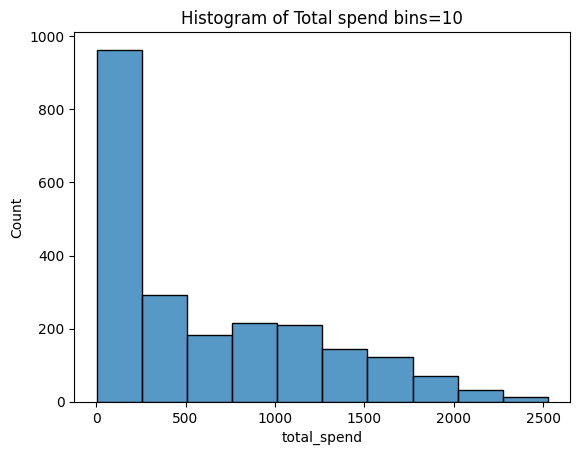

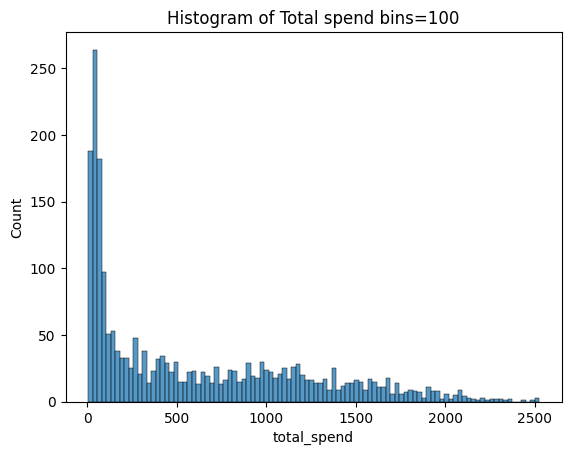

In [90]:
# Problem 4(a): your code here
sns.histplot(superstore['total_spend'],bins=10)
plt.title('Histogram of Total spend bins=10')
plt.show()
sns.histplot(superstore['total_spend'],bins=100)
plt.title('Histogram of Total spend bins=100')
plt.show()


**Your answer:**
This data is right skewed because most of the data is on the left. The mean is skewed to the right of the median because it is greatly affected by the larger values on the right. This is why the mean is greater than the median: Mean 605.798 Median 396.0

**(b) (3 points)** Make a scatterplot of `total_spend` (y) against `Income` (x). One customer makes the plot nearly unreadable. Find that customer (report the `Id` and `Income`), then build a mask that keeps customers with an income **below 200,000**, and redraw the scatterplot from the masked data with `hue='has_kids'`. Describe what the second plot shows, including what `hue` adds. How many customers does your mask keep, and why is it fewer than 2,239?

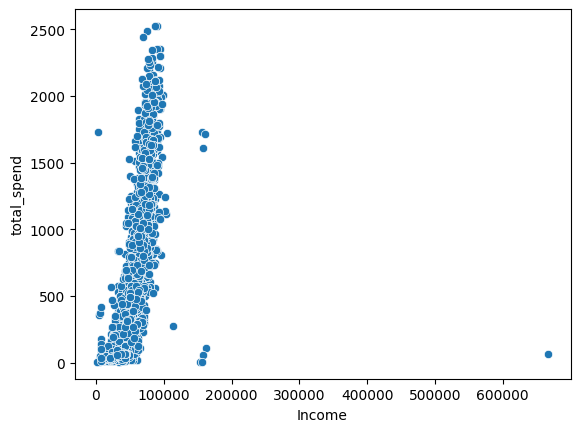

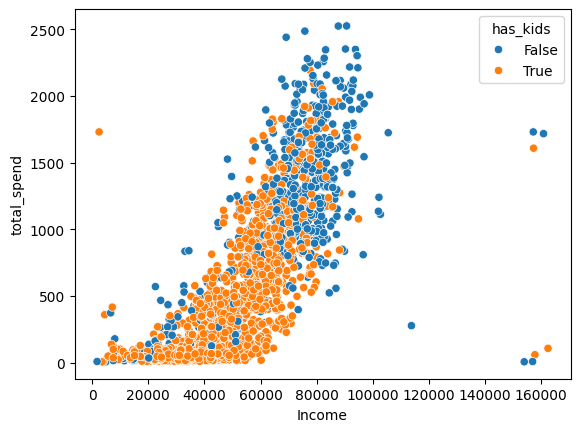

In [91]:
# Problem 4(b): your code here
sns.scatterplot(data=superstore, x='Income', y='total_spend')
plt.show()
mask_income = superstore['Income'] < 200000
sns.scatterplot(data=superstore[mask_income], x='Income', y='total_spend', hue='has_kids')
plt.show()


**Your answer:**
The second plot shows that there is a postive corelation between total_spend and income. The hue shows that those who have kids tend to have lower total_spend and income. Conversely, those who dont have kids tend to have higher total_spend and income.

**(c) (3 points)** Compute the correlation between `Income` and `total_spend` for **all** customers, and again for the customers your mask kept. Explain why removing **one** customer changes the correlation. Then answer: does this correlation show that higher income *causes* customers to spend more here? Give one specific alternative explanation.

In [ ]:
# Problem 4(c): your code here


**Your answer:**


---
## Problem 5. Report to the marketing team (4 points)
---

Write a short memo answering the team's question (*who are our big spenders, and who responds to our campaigns?*) for someone who has not seen your code.

- **Three findings** (1 point each), each one sentence, each backed by a specific number from Problems 1 to 4.
- **One caution** (1 point): a limitation of these data that should make the team careful with your findings. "More data would help" is not a caution.

**Your memo:**
